# LAB 03 — Image Enhancement and Intensity Transformations

**Name:** ______________________  **Roll No:** 2024-SET-__________

Lab Instructor: Engr. Fahad Nisar | Semester: Fifth | Session: 2024-28 (SE)

Department of Software Engineering, The University of Azad Jammu and Kashmir

**How this notebook is organised:** every section has a heading taken from the lab task, a short description of what we are doing, then the code (same methods as the lecture slides and the lecture notebook), then a short observation. The dry runs are written in the Word report, so they are not repeated here.

## Importing Libraries

Here we are loading the three libraries used in the lab. OpenCV (`cv`) reads images and has the enhancement functions, NumPy (`np`) handles pixel arrays, Matplotlib (`plt`) displays images and histograms.

In [29]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Loading and Validating the Image

Here we are reading the picture as an **8-bit grayscale** array (values 0 to 255), checking that it loaded correctly, and displaying its shape, dtype, minimum and maximum. The variable `img` is the original and is **never modified**; every result is stored in a new variable.

In [30]:
# Load the image as an 8-bit grayscale array
img = cv.imread("image.jpg", cv.IMREAD_GRAYSCALE)

# Stop with a clear message if the image was not found
if img is None:
    raise FileNotFoundError("Please add image.jpg in your project")

# Validation: 8-bit, one channel, at least 300 x 300
assert img.dtype == np.uint8 and img.ndim == 2
assert img.shape[0] >= 300 and img.shape[1] >= 300

# Display shape, dtype, minimum and maximum
print(img.shape, img.dtype, img.min(), img.max())

# Backup copy, used only to prove at the end that img was never changed
original = img.copy()

(678, 452) uint8 0 255


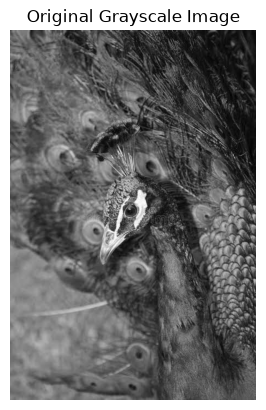

In [31]:
# Display the image with grayscale limits 0-255
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

## 1. Brightness adjustment

Here we are making the image brighter (β = +40) and darker (β = −40) with s = r + β. The pixels are first converted to `int16` so values such as 250 + 40 = 290 do not overflow, then `np.clip` limits them to 0–255, then they are converted back to `uint8`.

### 1.1 Brighter (+40) and darker (−40) using NumPy

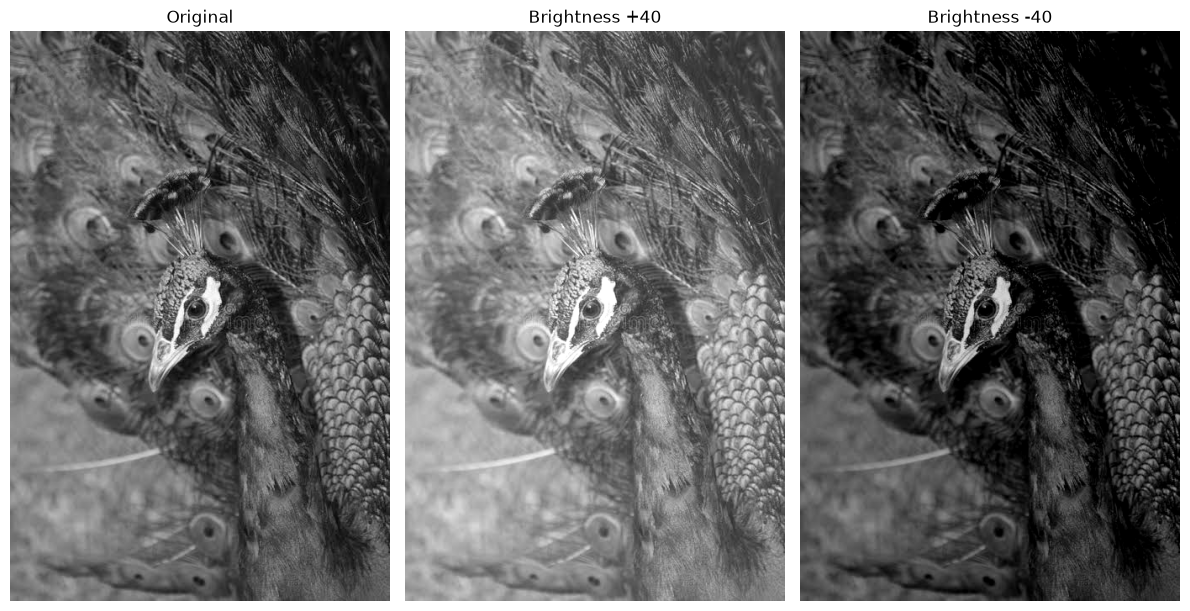

In [32]:
# Brightness +40: widen to int16, add 40, clip to 0-255, convert to uint8
bright_p40 = np.clip(img.astype(np.int16) + 40, 0, 255).astype(np.uint8)
# Brightness -40: same steps (negative values are clipped to 0)
dark_m40 = np.clip(img.astype(np.int16) - 40, 0, 255).astype(np.uint8)

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

# Images and their titles (original first, then the results)
images = [img, bright_p40, dark_m40]
titles = ["Original", "Brightness +40", "Brightness -40"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.2 Brightness +40 using nested loops

Here we are repeating the same +40 calculation by visiting every row and column. `int(...)` avoids unsigned 8-bit arithmetic and `min` / `max` do the clipping.

In [33]:
# Brightness value (beta) used in the loop version
brightness = 40

# Empty image of the same size to store the result
bright_loop = np.zeros_like(img)

# Image dimensions (rows and columns)
height, width = img.shape

# Visit every row and column
for row in range(height):
    for col in range(width):

        # Read original pixel value
        pixel = int(img[row, col])

        # Increase brightness
        new_pixel = pixel + brightness

        # Keep value between 0 and 255
        new_pixel = min(255, max(0, new_pixel))

        # Store new value
        bright_loop[row, col] = new_pixel

### 1.3 Verification: does the nested-loop result match the NumPy result?

In [34]:
# Verification: both methods must give exactly the same image
print("Nested loop result equals NumPy result:", np.array_equal(bright_loop, bright_p40))
print("Pixels that differ:", np.sum(bright_loop != bright_p40))

Nested loop result equals NumPy result: True
Pixels that differ: 0


In [35]:
# Count the pixels that were clipped
print("Pixels clipped to 255 after +40:", np.sum(bright_p40 == 255))
print("Pixels clipped to 0 after -40   :", np.sum(dark_m40 == 0))

Pixels clipped to 255 after +40: 1489
Pixels clipped to 0 after -40   : 43233


**Observation:** +40 makes the whole image lighter and −40 makes it darker. Pixels that hit 255 (or 0) are clipped, so different original values become the same value and that detail is lost. The nested loop gives exactly the same image as NumPy, but it is much slower.

## 2. Linear contrast from zero

Here we are applying s = α·r + β with α = 1.5 and β = 0. We use `float32` so the fractional multiplier works, clip to 0–255, and `astype(np.uint8)` truncates the fractions. Then we compare brightness and show which pixels were clipped (highlight clipping).

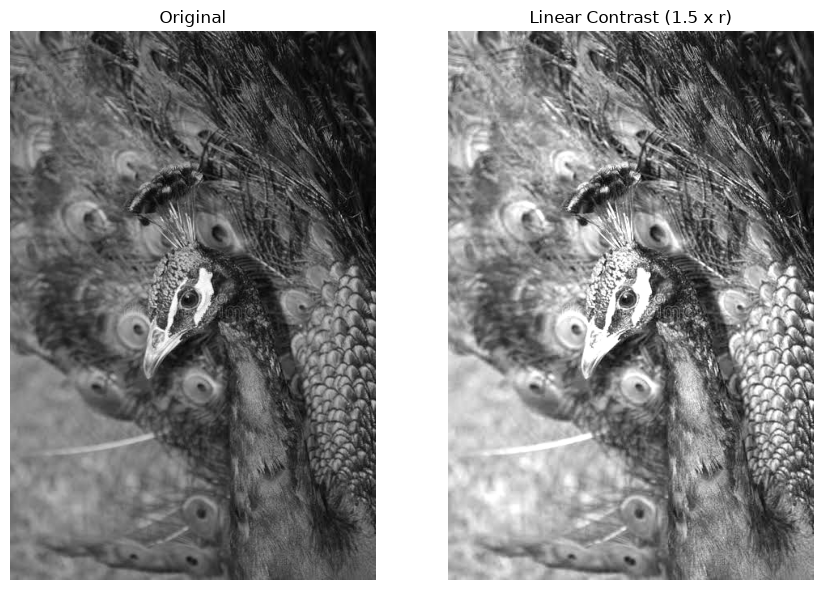

In [36]:
# alpha scales the intensities, beta shifts them
alpha, beta = 1.5, 0

# Linear contrast in float32, before clipping (so values above 255 can be detected)
raw_linear = alpha * img.astype(np.float32) + beta
# Clip to 0-255; astype(np.uint8) truncates the fractions
linear = np.clip(raw_linear, 0, 255).astype(np.uint8)

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 6))

# Images and their titles (original first, then the results)
images = [img, linear]
titles = ["Original", "Linear Contrast (1.5 x r)"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Mean brightness  original: 89.41 | linear: 133.07
Pixels clipped (raw value > 255): 5964 ( 1.95 % of the image )


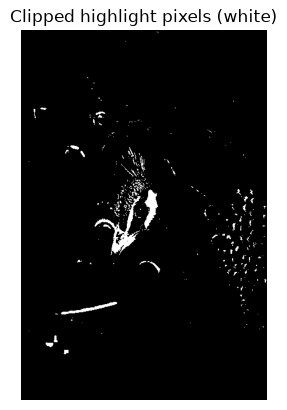

In [37]:
# Compare brightness with the original and count clipped pixels
print("Mean brightness  original:", round(img.mean(), 2), "| linear:", round(linear.mean(), 2))
print("Pixels clipped (raw value > 255):", np.sum(raw_linear > 255),
      "(", round(100 * np.mean(raw_linear > 255), 2), "% of the image )")

# Show the clipped (saturated) pixels in white
saturated = (raw_linear > 255).astype(np.uint8) * 255

# Display the image with grayscale limits 0-255
plt.imshow(saturated, cmap="gray", vmin=0, vmax=255)
plt.title("Clipped highlight pixels (white)")
plt.axis("off")
plt.show()

**Observation:** multiplying by 1.5 raises every non-zero pixel, so the image becomes noticeably brighter. Every pixel with r > 170 becomes more than 255 and is clipped, so bright highlight detail is lost.

## 3. Contrast centered at 128

Here we are applying s = (r − 128)·α + 128 with α = 1.5 and α = 0.5. Pixels move away from (α > 1) or toward (α < 1) the midpoint 128, and 128 itself stays unchanged. Then we compare both results with the linear contrast from zero.

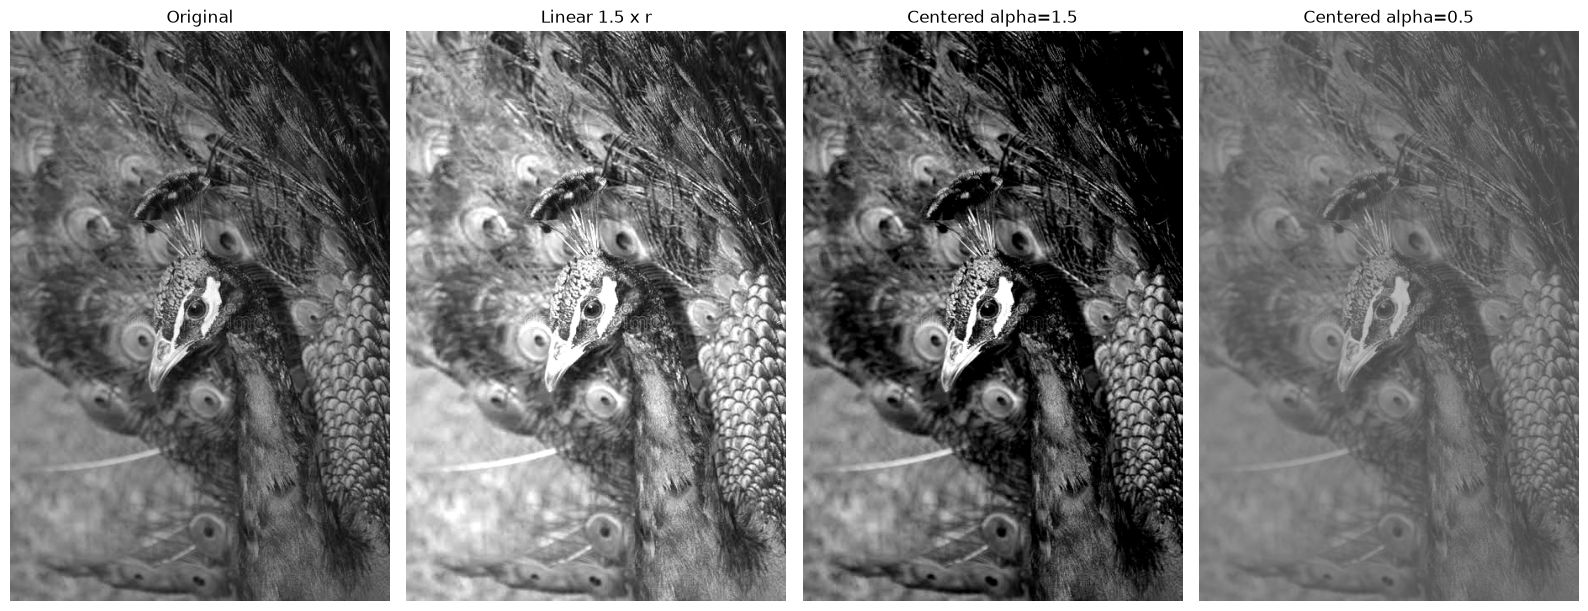

In [38]:
# Contrast centered at 128 with alpha = 1.5
centered_15 = np.clip(
    (img.astype(np.float32) - 128) * 1.5 + 128, 0, 255
).astype(np.uint8)

# Contrast centered at 128 with alpha = 0.5
centered_05 = np.clip(
    (img.astype(np.float32) - 128) * 0.5 + 128, 0, 255
).astype(np.uint8)

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 4, figsize=(16, 6))

# Images and their titles (original first, then the results)
images = [img, linear, centered_15, centered_05]
titles = ["Original", "Linear 1.5 x r", "Centered alpha=1.5", "Centered alpha=0.5"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
# Compare mean (brightness) and std (contrast) of the results
print("Original       mean =", round(img.mean(), 2), " std =", round(img.std(), 2))
print("Linear 1.5 x r mean =", round(linear.mean(), 2), " std =", round(linear.std(), 2))
print("Centered 1.5   mean =", round(centered_15.mean(), 2), " std =", round(centered_15.std(), 2))
print("Centered 0.5   mean =", round(centered_05.mean(), 2), " std =", round(centered_05.std(), 2))

Original       mean = 89.41  std = 41.34
Linear 1.5 x r mean = 133.07  std = 59.91
Centered 1.5   mean = 73.26  std = 56.11
Centered 0.5   mean = 108.46  std = 20.67


**Observation:** with α = 1.5 the dark pixels get darker and the light pixels get lighter, so contrast increases while the average brightness stays close to the original, unlike "from zero", which mainly brightens the image. With α = 0.5 the values are squeezed toward 128 and the image looks flat and gray.

## 4. Image negative

Here we are reversing light and dark with s = 255 − r. We also apply the negative a second time to confirm that we get the original back.

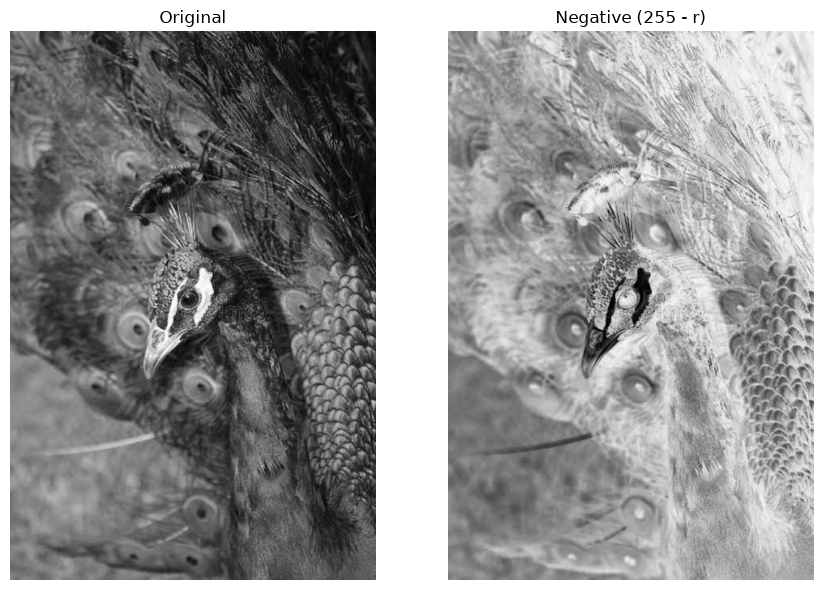

In [40]:
# Image negative: s = 255 - r
negative = 255 - img

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 6))

# Images and their titles (original first, then the results)
images = [img, negative]
titles = ["Original", "Negative (255 - r)"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [41]:
# Apply the negative a second time
double_negative = 255 - negative

# Verify that the double negative equals the original
print("Negative of the negative equals the original:", np.array_equal(double_negative, img))

Negative of the negative equals the original: True


**Observation:** the negative reverses all intensities. It helps inspection when important detail is dark on a dark background (for example in an X-ray), because inverted dark-gray detail is easier to see. Applying it twice restores the original exactly.

## 5. Gamma correction

Here we are applying the nonlinear rule s = 255·(r/255)^γ with γ = 0.5 and γ = 2.0. First normalize to 0–1, then apply the power, then scale back to 0–255. In this convention γ < 1 brightens and γ > 1 darkens.

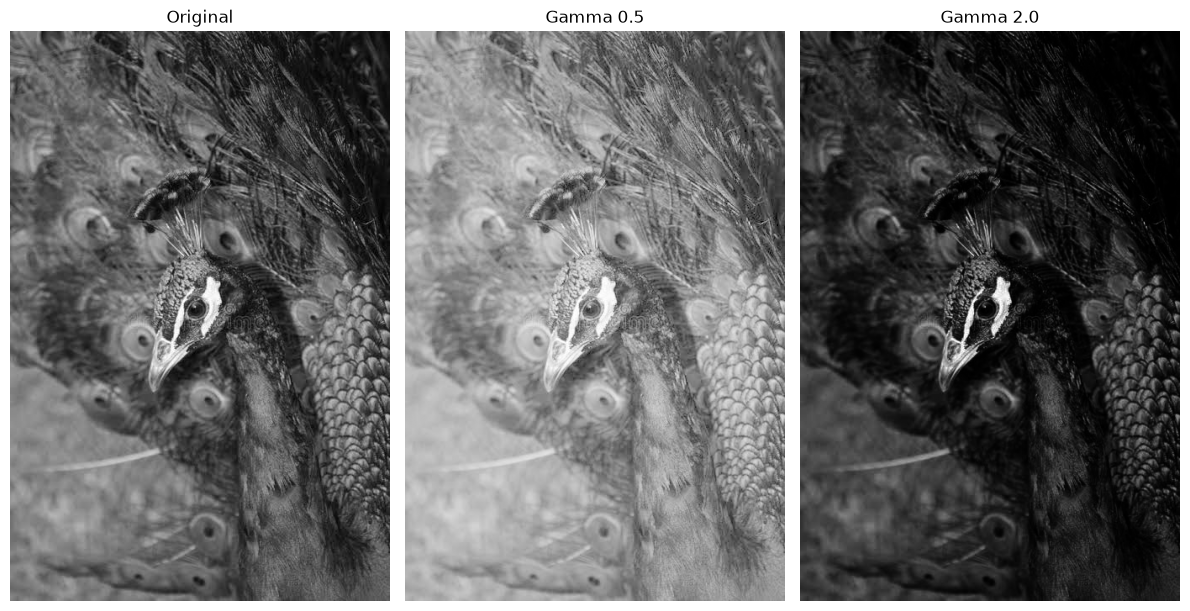

In [42]:
# Normalize pixel values to the range 0-1
normalized = img.astype(np.float32) / 255

# Gamma 0.5: power, scale back to 0-255, clip, truncate to uint8
gamma_05 = np.clip(255 * np.power(normalized, 0.5), 0, 255).astype(np.uint8)
# Gamma 2.0: same steps with exponent 2.0
gamma_20 = np.clip(255 * np.power(normalized, 2.0), 0, 255).astype(np.uint8)

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

# Images and their titles (original first, then the results)
images = [img, gamma_05, gamma_20]
titles = ["Original", "Gamma 0.5", "Gamma 2.0"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5.1 Effect on dark regions and check that 0 and 255 stay fixed

In [43]:
# Dark regions: pixels whose original value is below 64
dark_mask = img < 64

print("Mean of originally dark pixels (r < 64):")
print("  Original :", round(img[dark_mask].mean(), 2))
print("  gamma 0.5:", round(gamma_05[dark_mask].mean(), 2))
print("  gamma 2.0:", round(gamma_20[dark_mask].mean(), 2))

# 0 and 255 must stay fixed
fixed = np.array([0, 255], dtype=np.float32) / 255
print("gamma 0.5 ->", np.clip(255 * np.power(fixed, 0.5), 0, 255).astype(np.uint8))
print("gamma 2.0 ->", np.clip(255 * np.power(fixed, 2.0), 0, 255).astype(np.uint8))

Mean of originally dark pixels (r < 64):
  Original : 39.58
  gamma 0.5: 97.6
  gamma 2.0: 6.61
gamma 0.5 -> [  0 255]
gamma 2.0 -> [  0 255]


**Observation:** γ = 0.5 lifts shadows and mid-tones strongly, so dark regions become much more visible, while γ = 2.0 makes dark regions even darker. The values 0 and 255 never change.

## 6. Grayscale histogram

Here we are counting how many pixels have each intensity from 0 to 255 and plotting it with 256 bins over the range 0–256.

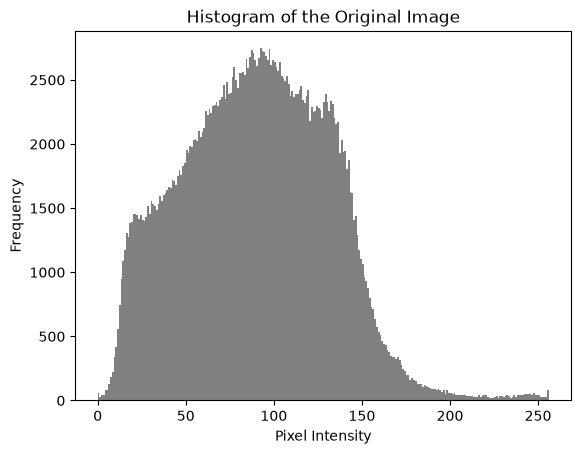

In [44]:
# Plot a 256-bin histogram over the range 0-256
plt.hist(img.ravel(), bins = 256, range = (0, 256), color="gray")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Histogram of the Original Image")
plt.show()

In [45]:
# Share of dark, middle and bright pixels
print("Mean intensity:", round(img.mean(), 2))
print("Dark pixels   (r < 85)        :", round(100 * np.mean(img < 85), 1), "%")
print("Mid pixels    (85 <= r < 170) :", round(100 * np.mean((img >= 85) & (img < 170)), 1), "%")
print("Bright pixels (r >= 170)      :", round(100 * np.mean(img >= 170), 1), "%")

Mean intensity: 89.41
Dark pixels   (r < 85)        : 45.4 %
Mid pixels    (85 <= r < 170) : 52.5 %
Bright pixels (r >= 170)      : 2.1 %


**Interpretation:** the pixels are concentrated in the lower and middle part of the range (mean about 89, only about 2% of pixels at 170 or above), so the image is fairly dark and uses little of the bright end. The histogram only counts intensities; it does not show where the pixels are located.

## 7. Global histogram equalization

Here we are using `cv.equalizeHist` to spread the intensities over the full 0–255 range, then showing the original and equalized images together with both histograms.

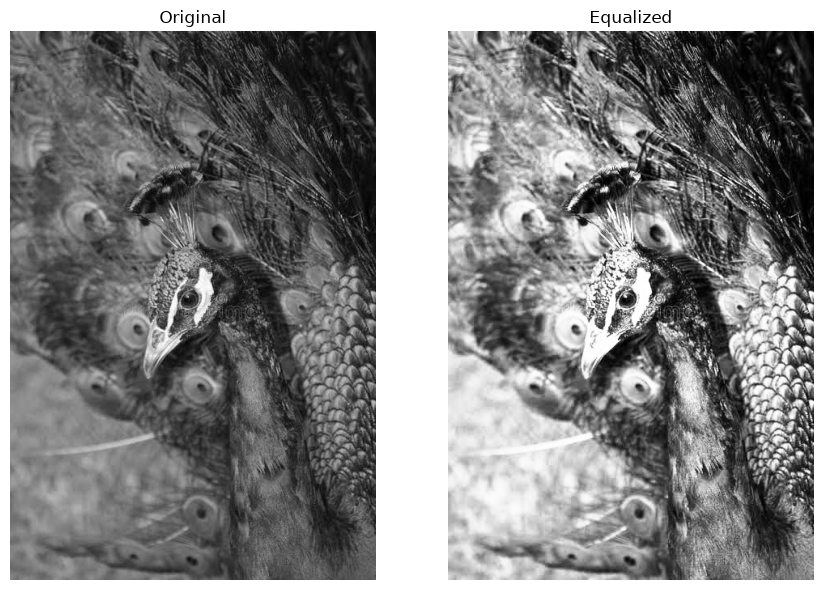

In [46]:
# Global histogram equalization with OpenCV
equalized = cv.equalizeHist(img)

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 6))

# Images and their titles (original first, then the results)
images = [img, equalized]
titles = ["Original", "Equalized"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

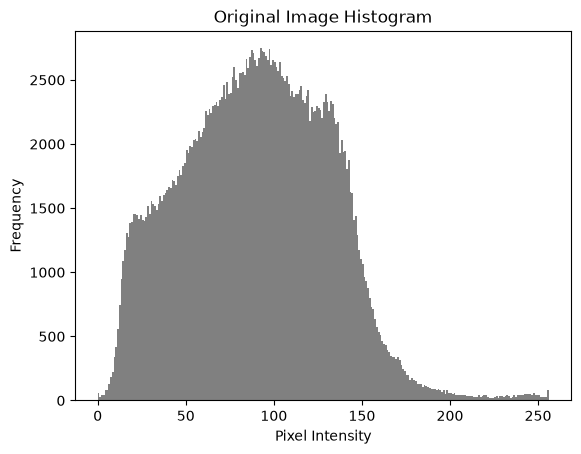

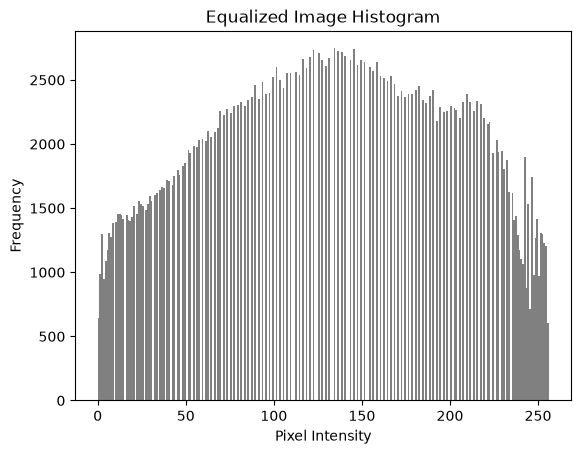

In [47]:
# Plot a 256-bin histogram over the range 0-256
plt.hist(img.ravel(), bins = 256, range = (0, 256), color="gray")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Original Image Histogram")
plt.show()

# Plot a 256-bin histogram over the range 0-256
plt.hist(equalized.ravel(), bins = 256, range = (0, 256), color="gray")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Equalized Image Histogram")
plt.show()

In [48]:
# Dry run 7: compare the hand result with OpenCV
dry = np.array([[50, 50, 100, 150]], dtype=np.uint8)
opencv_out = cv.equalizeHist(dry).ravel().tolist()
print("Hand result, method 1 (255 x CDF)       :", [128, 128, 191, 255])
print("Hand result, method 2 (CDF - CDFmin)    :", [0, 0, 128, 255])
print("OpenCV cv.equalizeHist                  :", opencv_out)
print("Method 2 matches OpenCV:", opencv_out == [0, 0, 128, 255])

Hand result, method 1 (255 x CDF)       : [128, 128, 191, 255]
Hand result, method 2 (CDF - CDFmin)    : [0, 0, 128, 255]
OpenCV cv.equalizeHist                  : [0, 0, 128, 255]
Method 2 matches OpenCV: True


### 7.1 Does noise become stronger?

Here we are measuring the average difference between neighbouring pixels. A larger value means more local variation, which includes noise and texture.

In [49]:
# Average difference between neighbouring pixels (higher = more local variation and noise)
rough_img = (np.abs(np.diff(img.astype(np.int16), axis=0)).mean() + np.abs(np.diff(img.astype(np.int16), axis=1)).mean()) / 2
# Same measure for the equalized image
rough_eq = (np.abs(np.diff(equalized.astype(np.int16), axis=0)).mean() + np.abs(np.diff(equalized.astype(np.int16), axis=1)).mean()) / 2

# Compare mean, std and neighbour difference
print("Original  : mean =", round(img.mean(), 2), " std =", round(img.std(), 2), " neighbour difference =", round(rough_img, 2))
print("Equalized : mean =", round(equalized.mean(), 2), " std =", round(equalized.std(), 2), " neighbour difference =", round(rough_eq, 2))

Original  : mean = 89.41  std = 41.34  neighbour difference = 8.09
Equalized : mean = 128.32  std = 73.6  neighbour difference = 14.0


**Discussion:** equalization spreads the intensities over the full range, so contrast increases and dark areas show more detail. But the brightness changes and the image can look unnatural. The neighbour-difference value goes up, which shows that local variation, including noise and the grass texture, is amplified.

## 8. CLAHE

Here we are applying Contrast Limited Adaptive Histogram Equalization with `clipLimit = 2.0` and `tileGridSize = (8, 8)`, and comparing it with the original and with global equalization. `(8, 8)` means the image is split into 8 × 8 = **64 tiles**; it does **not** mean each tile is 8 × 8 pixels.

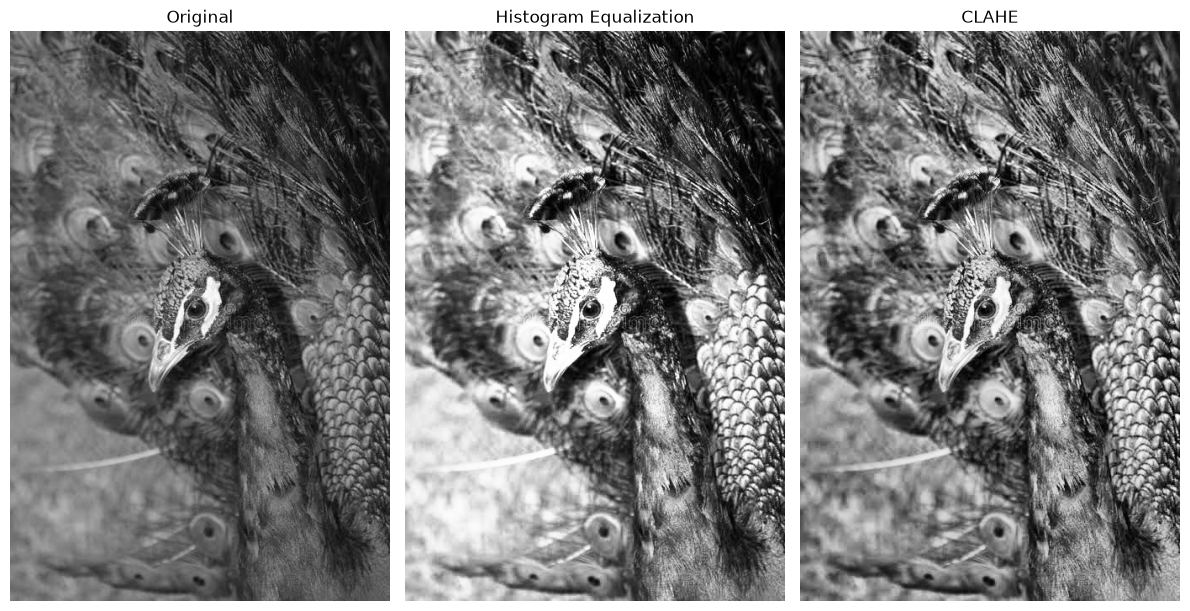

In [50]:
# Normal histogram equalization
equalized = cv.equalizeHist(img)

# Create CLAHE processor
clahe = cv.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Apply CLAHE
enhanced = clahe.apply(img)

# Compare results
# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

# Images and their titles (original first, then the results)
images = [img, equalized, enhanced]
titles = ["Original", "Histogram Equalization", "CLAHE"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

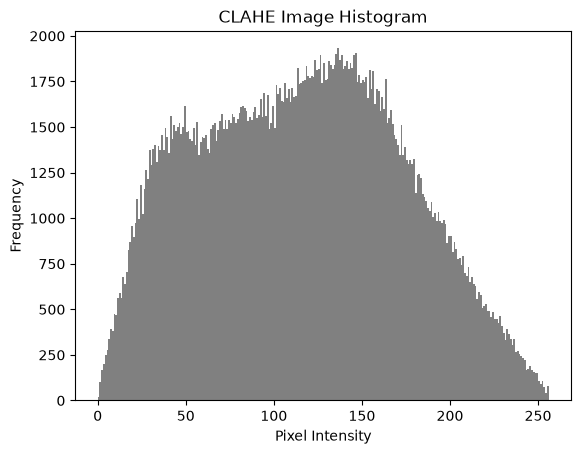

Neighbour difference  original: 8.09 | global: 14.0 | CLAHE: 15.05


In [51]:
# Plot a 256-bin histogram over the range 0-256
plt.hist(enhanced.ravel(), bins = 256, range = (0, 256), color="gray")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("CLAHE Image Histogram")
plt.show()

# Same measure for the CLAHE image
rough_cl = (np.abs(np.diff(enhanced.astype(np.int16), axis=0)).mean() + np.abs(np.diff(enhanced.astype(np.int16), axis=1)).mean()) / 2
print("Neighbour difference  original:", round(rough_img, 2), "| global:", round(rough_eq, 2), "| CLAHE:", round(rough_cl, 2))

**Discussion:** CLAHE equalizes each tile separately and limits the amplification with `clipLimit`, so it adapts to uneven lighting (bright feathers versus the shadowed neck and background) and usually looks more natural than global equalization, although the neighbour-difference value shows it also increases fine detail and noise.

## 9. Fixed binary thresholding

Here we are converting the image to only two values using `cv.THRESH_BINARY` with T = 127: if r > 127 the output is 255, otherwise 0. We display the binary image and report its unique values.

Threshold used: 127.0
Unique values : [  0 255]
White pixels  : 59757 ( 19.5 % )


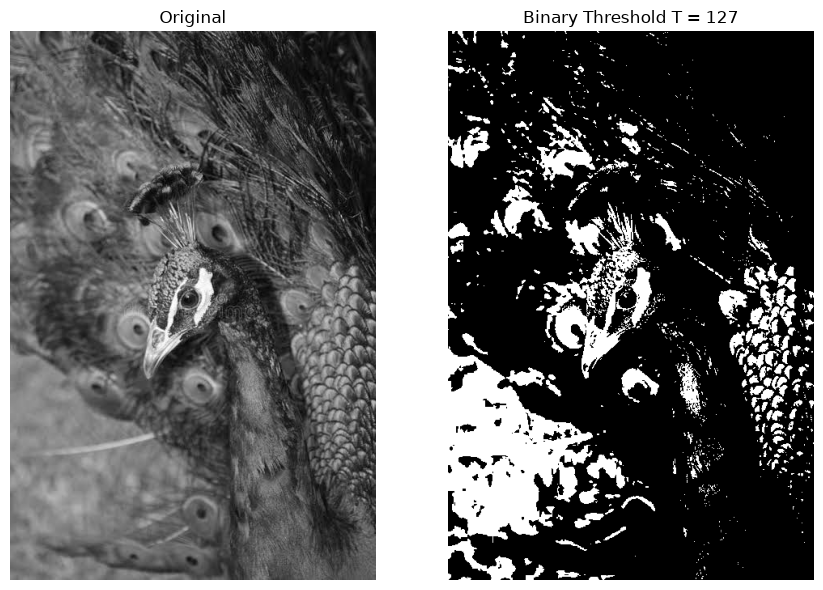

In [52]:
# Fixed binary threshold: output 255 if r > 127, otherwise 0
threshold_used, binary = cv.threshold(img, 127, 255, cv.THRESH_BINARY)

# Report the threshold, the unique values and the white-pixel count
print("Threshold used:", threshold_used)
print("Unique values :", np.unique(binary))
print("White pixels  :", np.sum(binary == 255), "(", round(100 * np.mean(binary == 255), 1), "% )")

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 6))

# Images and their titles (original first, then the results)
images = [img, binary]
titles = ["Original", "Binary Threshold T = 127"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Observation:** the output contains only 0 and 255. A fixed threshold ignores the image content, so how well it separates the dark and bright parts depends on the chosen T.

## 10. Otsu thresholding

Here we are letting OpenCV choose the global threshold automatically with `cv.THRESH_BINARY + cv.THRESH_OTSU` (the threshold value we pass, 0, is ignored). We report the returned threshold and compare the mask with the fixed T = 127 mask.

Otsu threshold returned: 88.0
Unique values          : [  0 255]
White pixels  fixed    : 59757 ( 19.5 % )
White pixels  Otsu     : 156503 ( 51.1 % )
Pixels that differ between the two masks: 96746 ( 31.6 % )


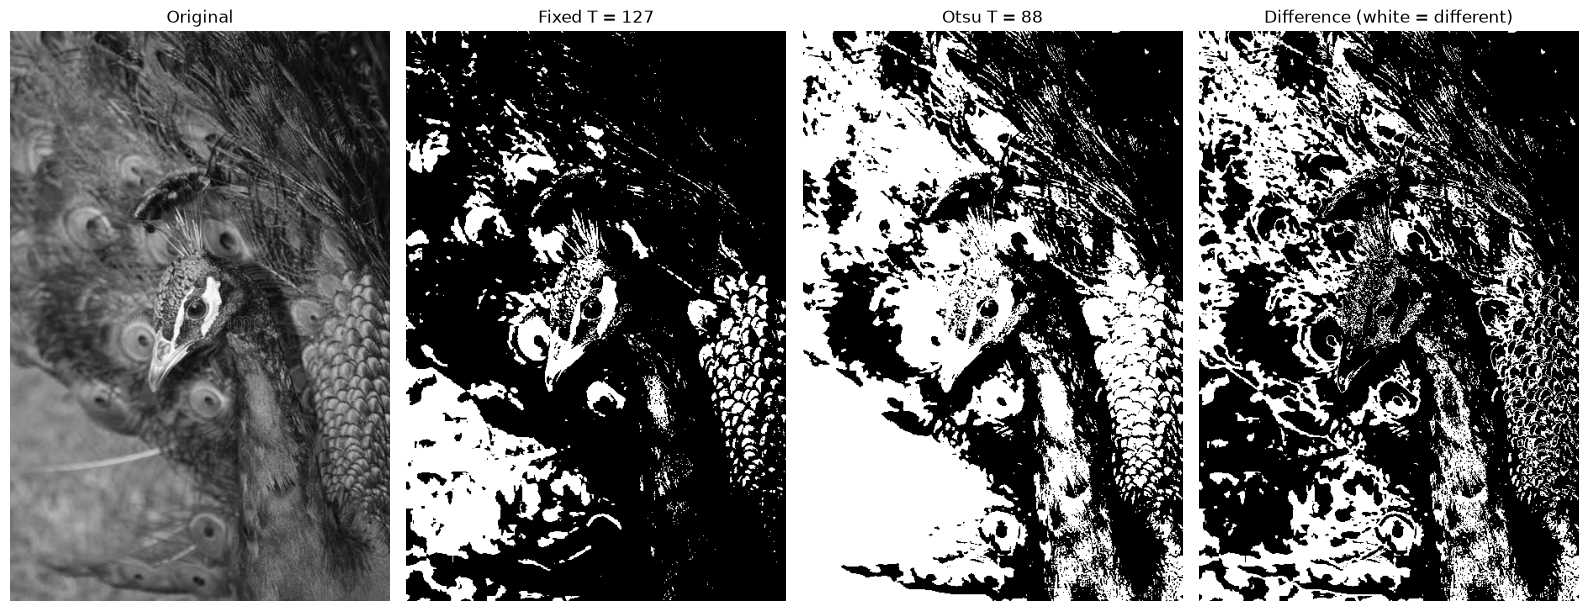

In [53]:
# Otsu: OpenCV chooses the global threshold automatically
otsu_t, otsu = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Report the threshold and compare it with the fixed-threshold mask
print("Otsu threshold returned:", otsu_t)
print("Unique values          :", np.unique(otsu))
print("White pixels  fixed    :", np.sum(binary == 255), "(", round(100 * np.mean(binary == 255), 1), "% )")
print("White pixels  Otsu     :", np.sum(otsu == 255), "(", round(100 * np.mean(otsu == 255), 1), "% )")
print("Pixels that differ between the two masks:", np.sum(binary != otsu),
      "(", round(100 * np.mean(binary != otsu), 1), "% )")

# White = pixels where the two masks disagree
difference = (binary != otsu).astype(np.uint8) * 255

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 4, figsize=(16, 6))

# Images and their titles (original first, then the results)
images = [img, binary, otsu, difference]
titles = ["Original", "Fixed T = 127", "Otsu T = " + str(int(otsu_t)), "Difference (white = different)"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [54]:
# Dry run 10: verify the hand-calculated Otsu result with OpenCV
dry = np.array([[0, 1], [4, 5]], dtype=np.uint8)
t, mask = cv.threshold(dry, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Hand result : T = 1, mask [0, 0, 255, 255]")
print("OpenCV T    :", t)
print("OpenCV mask :", mask.ravel().tolist())
print("Matches the hand prediction:", t == 1 and mask.ravel().tolist() == [0, 0, 255, 255])

Hand result : T = 1, mask [0, 0, 255, 255]
OpenCV T    : 1.0
OpenCV mask : [0, 0, 255, 255]
Matches the hand prediction: True


**Observation:** Otsu picks the threshold from the image's own histogram by maximizing the separation between the dark and bright classes, so it is lower than 127 here and marks many more pixels as white. The difference image shows where the two masks disagree.

## 11. Adaptive Gaussian thresholding

Here we are using `cv.adaptiveThreshold` with Gaussian weighting, binary output, `blockSize = 11` and `C = 2`. Each pixel gets its own threshold (Gaussian-weighted mean of its 11 × 11 neighbourhood minus C). We compare it with the fixed and Otsu results.

Unique values: [  0 255]
White pixels  fixed   : 19.5 %
White pixels  Otsu    : 51.1 %
White pixels  adaptive: 58.2 %


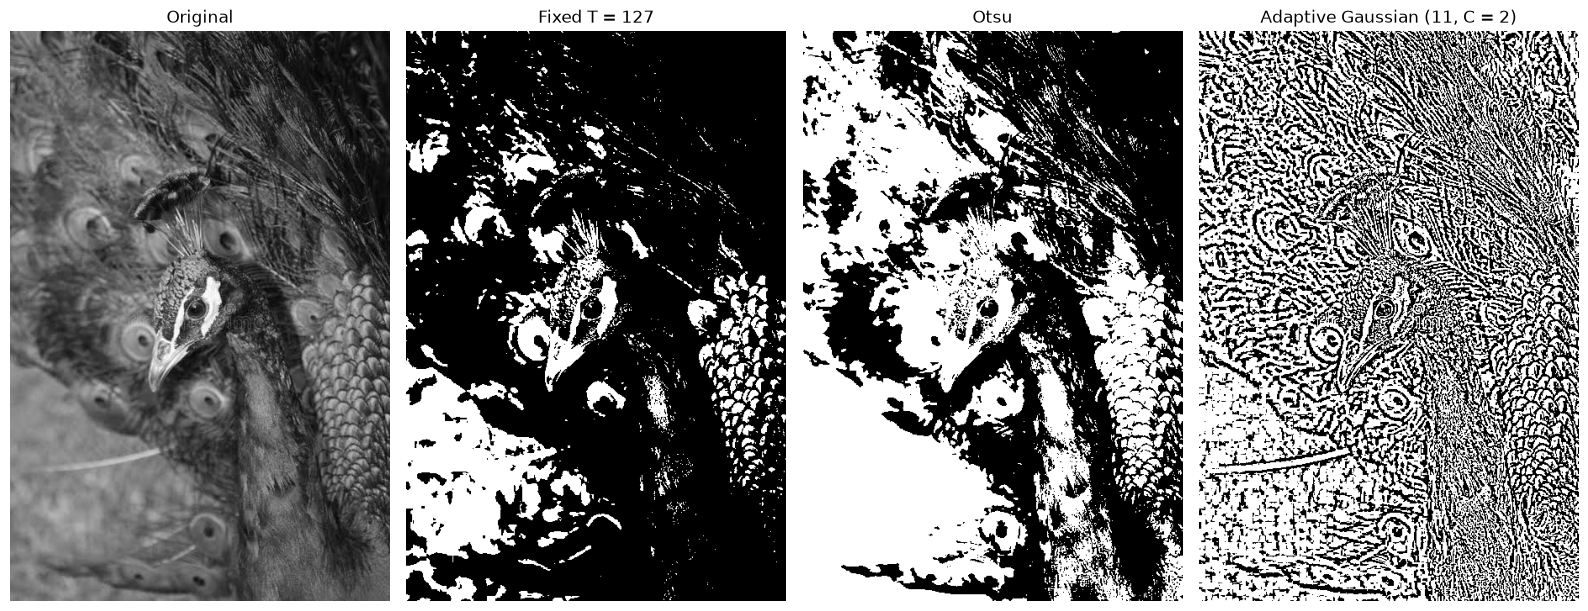

In [55]:
# Adaptive Gaussian threshold: 11 x 11 neighbourhood, C = 2
adaptive = cv.adaptiveThreshold(
    img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY, 11, 2
)

# Compare the percentage of white pixels in the three methods
print("Unique values:", np.unique(adaptive))
print("White pixels  fixed   :", round(100 * np.mean(binary == 255), 1), "%")
print("White pixels  Otsu    :", round(100 * np.mean(otsu == 255), 1), "%")
print("White pixels  adaptive:", round(100 * np.mean(adaptive == 255), 1), "%")

# Create one row of subplots to compare the images side by side
fig, axes = plt.subplots(1, 4, figsize=(16, 6))

# Images and their titles (original first, then the results)
images = [img, binary, otsu, adaptive]
titles = ["Original", "Fixed T = 127", "Otsu", "Adaptive Gaussian (11, C = 2)"]

# Show every image with grayscale limits 0-255 and a clear title
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Observation:** the adaptive method keeps local edges and texture (the feather pattern) even where the lighting differs, while fixed and Otsu use one value for the whole image and give large uniform black or white regions. Local thresholds help for unevenly lit images such as shadowed documents; on a natural photo they also pick up fine texture and noise.

## Final Check: the original image was never changed

In [56]:
# Confirm that the original image was not modified
print("img is identical to the backup copy:", np.array_equal(img, original))

img is identical to the backup copy: True


## Summary

- Safe arithmetic: widen the type (`int16` or `float32`), `np.clip(..., 0, 255)`, then `astype(np.uint8)` (which truncates fractions).
- Brightness shifts all intensities; contrast changes the distance from the midpoint 128; the negative inverts; gamma < 1 brightens and gamma > 1 darkens, with 0 and 255 fixed.
- Global equalization works on the whole histogram; CLAHE works on 8 × 8 = 64 tiles with a clip limit.
- Fixed threshold uses T = 127; Otsu chooses T automatically; adaptive Gaussian uses a local threshold per pixel.